In [12]:
from pathlib import Path
import importlib, json, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score

SPLIT = "val"
MAX_CLIPS = 120
SEED = 42
USE_CUDA = True
FORCE_RECOMPUTE_LOGITS = False

VIDEO_CHECKPOINT_OVERRIDE = "Audio/Video_checkpoints/Pruned_10/prune_0p1_full.pt"
VIDEO_CODE_DIR_OVERRIDE = None
METADATA_DIR_OVERRIDE = None
CLIPS_DIR_OVERRIDE = None

# Missing Benchmark I clips are downloaded selectively into CLIPS_DIR.
DOWNLOAD_MISSING_CLIPS = True
MAMMALPS_ZIP_URL = "https://zenodo.org/records/15588220/files/mammalps_v1.zip"
LOCAL_ARCHIVE_OVERRIDE = None  # Optional existing mammalps_v1.zip, skips network download.

CONFIDENCE_THRESHOLDS = [0.0, 0.5, 0.65, 0.75, 0.85, 0.90, 0.95, 0.99, 1.0]
BATTERY_FRAME_CAPS = {1.00: 8, 0.70: 4, 0.40: 2, 0.20: 1}
BATTERY_EXAMPLE_THRESHOLDS = {1.00: 0.95, 0.70: 0.85, 0.40: 0.65, 0.20: 0.50}


def find_root():
    for base in (Path.cwd(), *Path.cwd().parents):
        has_data = any(
            (base / data / "metadata" / filename).is_file()
            for data in ("data", "Data")
            for filename in ("val.csv", "benchmark_2_audio_model_manifest.csv")
        )
        has_video = any((base / dirname / "video.py").is_file()
                        for dirname in ("Video", "video")) or (base / "video.py").is_file()
        if has_data and has_video:
            return base.resolve()
    raise FileNotFoundError("Project root not found. Open this notebook inside a project containing Video/video.py and data/metadata/val.csv (or the Benchmark II audio manifest).")

ROOT = find_root()
OUT_DIR = ROOT / "Audio" / "results" / "video_activity_pareto"
OUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if USE_CUDA and torch.cuda.is_available() else "cpu")
print("Project:", ROOT, "| Inference device:", DEVICE)

Project: C:\Users\benja\Documents\CS_Master\Big Data at the Edge\Big_Data_at_the_Edge_Project | Inference device: cuda


In [13]:
def relative_to_root(value):
    if value is None: return None
    path = Path(value)
    return path if path.is_absolute() else ROOT / path

video_dirs = [ROOT / "Video", ROOT / "video", ROOT]
VIDEO_DIR = relative_to_root(VIDEO_CODE_DIR_OVERRIDE) or next((p for p in video_dirs if (p / "video.py").is_file()), None)
CHECKPOINT = relative_to_root(VIDEO_CHECKPOINT_OVERRIDE)
metadata_candidates = [ROOT / "data" / "metadata", ROOT / "Video" / "data" / "mammalps_v1" / "benchmark_1" / "metadata",
                       ROOT / "data" / "mammalps_v1" / "benchmark_1" / "metadata"]
METADATA_DIR = relative_to_root(METADATA_DIR_OVERRIDE) or next((p for p in metadata_candidates if (p / f"{SPLIT}.csv").is_file()), None)
clip_candidates = [ROOT / "data" / "mammalps_v1" / "benchmark_1" / "clips",
                   ROOT / "Video" / "data" / "mammalps_v1" / "benchmark_1" / "clips",
                   ROOT / "data" / "benchmark_1" / "clips"]
# Prefer a pre-existing clip folder; if none exists, create the canonical folder.
CLIPS_DIR = relative_to_root(CLIPS_DIR_OVERRIDE) or clip_candidates[0]
print("Video code:", VIDEO_DIR)
print("Checkpoint:", CHECKPOINT)
print("Metadata:", METADATA_DIR)
if VIDEO_DIR is None: raise FileNotFoundError("Video/video.py not found. Set VIDEO_CODE_DIR_OVERRIDE")
if not CHECKPOINT.is_file():
    raise FileNotFoundError(
        f"Trained video checkpoint not found: {CHECKPOINT}. "
        "Provide a compatible checkpoint at this path or change VIDEO_CHECKPOINT_OVERRIDE."
    )
if METADATA_DIR is None:
    raise FileNotFoundError(
        f"Benchmark I {SPLIT}.csv not found. Supply the activity-labeled metadata and set METADATA_DIR_OVERRIDE."
    )

metadata = pd.read_csv(METADATA_DIR / f"{SPLIT}.csv")
assert {"video_path", "activity"}.issubset(metadata.columns)
assert len(metadata) and not metadata["video_path"].duplicated().any()
if MAX_CLIPS is not None:
    metadata = metadata.sample(n=min(MAX_CLIPS, len(metadata)), random_state=SEED)
metadata = metadata.reset_index(drop=True)
# Reuse the existing location containing the most selected files, if multiple
# recognized clip directories already exist and no override was specified.
if CLIPS_DIR_OVERRIDE is None:
    CLIPS_DIR = max(clip_candidates, key=lambda base: sum(
        (base / relative).is_file() for relative in metadata.video_path
    ))
missing = [s for s in metadata["video_path"] if not (CLIPS_DIR / s).is_file()]
print("Labeled clip folder:", CLIPS_DIR)
print(f"Selected {len(metadata)} labeled {SPLIT} clips, missing physical clips: {len(missing)}")
print("Classes selected:", metadata.activity.value_counts().to_dict())
if missing:
    display(pd.DataFrame({"missing_clip_example": missing[:6]}))
    print("Missing clips will be retrieved from the MammAlps Benchmark I archive in the next cell.")

Video code: C:\Users\benja\Documents\CS_Master\Big Data at the Edge\Big_Data_at_the_Edge_Project\Video
Checkpoint: C:\Users\benja\Documents\CS_Master\Big Data at the Edge\Big_Data_at_the_Edge_Project\Audio\Video_checkpoints\Pruned_10\prune_0p1_full.pt
Metadata: C:\Users\benja\Documents\CS_Master\Big Data at the Edge\Big_Data_at_the_Edge_Project\data\metadata
Labeled clip folder: C:\Users\benja\Documents\CS_Master\Big Data at the Edge\Big_Data_at_the_Edge_Project\data\mammalps_v1\benchmark_1\clips
Selected 120 labeled val clips, missing physical clips: 0
Classes selected: {'foraging': 66, 'vigilance': 33, 'unknown': 15, 'escaping': 2, 'camera_reaction': 2, 'chasing': 1, 'courtship': 1}


In [3]:
import contextlib
import shutil
import subprocess
import zipfile
import importlib.util
import posixpath

# Only allow clip paths underneath the expected labeled clip folder.
def clean_clip_path(relative):
    name = str(relative).replace("\\", "/").lstrip("/")
    parts = name.split("/")
    if (not name.lower().endswith(".mp4") or ".." in parts or "." in parts
            or len(parts) < 2 or any(not p for p in parts)):
        raise ValueError(f"Invalid relative Benchmark I clip path: {relative!r}")
    return name

selected_paths = [clean_clip_path(p) for p in metadata["video_path"]]
missing_paths = [p for p in selected_paths
                 if not (CLIPS_DIR / Path(p)).is_file()
                 or (CLIPS_DIR / Path(p)).stat().st_size == 0]

if not missing_paths:
    print(f"All {len(selected_paths)} selected clips are cached in {CLIPS_DIR}.")
elif not DOWNLOAD_MISSING_CLIPS:
    raise FileNotFoundError(
        f"{len(missing_paths)} selected labeled clips are missing from {CLIPS_DIR}. "
        "Set DOWNLOAD_MISSING_CLIPS=True to retrieve them from the official archive."
    )
else:
    local_archive = relative_to_root(LOCAL_ARCHIVE_OVERRIDE)
    if local_archive is not None:
        if not local_archive.is_file():
            raise FileNotFoundError(f"Local ZIP archive not found: {local_archive}")
        archive_context = zipfile.ZipFile(local_archive, mode="r")
        print("Reading ZIP index from local archive:", local_archive)
    else:
        if importlib.util.find_spec("remotezip") is None:
            print("Installing remotezip for selective HTTP range downloads ...")
            subprocess.check_call([sys.executable, "-m", "pip", "install", "remotezip"])
        from remotezip import RemoteZip
        print("Opening remote MammAlps archive (only the ZIP index is requested first):")
        print(MAMMALPS_ZIP_URL)
        archive_context = RemoteZip(MAMMALPS_ZIP_URL, timeout=120)

    print(f"Missing labeled clips: {len(missing_paths)} / {len(selected_paths)}")
    CLIPS_DIR.mkdir(parents=True, exist_ok=True)
    with archive_context as archive:
        # ZIP member paths may include a top-level folder (e.g. mammalps_v1/).
        # Match the segment after benchmark_1/clips/ to the CSV video_path.
        member_map = {}
        for info in archive.infolist():
            entry = info.filename.replace("\\", "/")
            tag = "benchmark_1/clips/"
            at = entry.find(tag)
            if at < 0 or info.is_dir():
                continue
            relative = entry[at + len(tag):]
            if relative and relative not in member_map:
                member_map[relative] = info

        archive_missing = [p for p in missing_paths if p not in member_map]
        if archive_missing:
            examples = list(member_map)[:3]
            raise FileNotFoundError(
                f"{len(archive_missing)} requested clip paths were not found in the archive, "
                f"including {archive_missing[:3]}. "
                f"Example ZIP clip paths: {examples}. "
                "Check that the metadata and ZIP correspond to the same MammAlps dataset version."
            )

        estimated_mb = sum(member_map[p].compress_size for p in missing_paths) / (1024**2)
        print(f"Compressed size of missing selected members: approximately {estimated_mb:.1f} MiB")
        print("Existing clips remain unchanged. Downloading and extracting selected members ...")
        started = time.perf_counter()
        for idx, relative in enumerate(missing_paths, 1):
            info = member_map[relative]
            destination = CLIPS_DIR / Path(relative)
            destination.parent.mkdir(parents=True, exist_ok=True)
            partial = destination.with_suffix(destination.suffix + ".download")
            try:
                with archive.open(info) as source, partial.open("wb") as target:
                    shutil.copyfileobj(source, target, length=1024 * 1024)
                if partial.stat().st_size != info.file_size:
                    raise IOError(
                        f"Incomplete extraction for {relative}: "
                        f"{partial.stat().st_size} bytes, expected {info.file_size} bytes"
                    )
                partial.replace(destination)
            except Exception:
                partial.unlink(missing_ok=True)
                raise
            if idx == 1 or idx % 10 == 0 or idx == len(missing_paths):
                print(f"Cached {idx}/{len(missing_paths)} clips "
                      f"({time.perf_counter()-started:.1f} s elapsed)", flush=True)

remaining = [p for p in selected_paths
             if not (CLIPS_DIR / Path(p)).is_file()
             or (CLIPS_DIR / Path(p)).stat().st_size == 0]
if remaining:
    raise FileNotFoundError(f"Missing after extraction: {remaining[:5]}")
print(f"Ready: {len(selected_paths)} cropped activity clips under {CLIPS_DIR}")

Opening remote MammAlps archive (only the ZIP index is requested first):
https://zenodo.org/records/15588220/files/mammalps_v1.zip
Missing labeled clips: 120 / 120
Compressed size of missing selected members: approximately 29.6 MiB
Existing clips remain unchanged. Downloading and extracting selected members ...
Cached 1/120 clips (0.2 s elapsed)
Cached 10/120 clips (3.8 s elapsed)
Cached 20/120 clips (7.4 s elapsed)
Cached 30/120 clips (10.9 s elapsed)
Cached 40/120 clips (14.2 s elapsed)
Cached 50/120 clips (17.5 s elapsed)
Cached 60/120 clips (21.1 s elapsed)
Cached 70/120 clips (24.4 s elapsed)
Cached 80/120 clips (28.1 s elapsed)
Cached 90/120 clips (31.6 s elapsed)
Cached 100/120 clips (35.3 s elapsed)
Cached 110/120 clips (39.1 s elapsed)
Cached 120/120 clips (43.1 s elapsed)
Ready: 120 cropped activity clips under C:\Users\benja\Documents\CS_Master\Big Data at the Edge\Big_Data_at_the_Edge_Project\data\mammalps_v1\benchmark_1\clips


In [4]:
sys.path.insert(0, str(VIDEO_DIR.resolve()))
video_module = importlib.import_module("video")
from torchvision.models import MobileNet_V3_Large_Weights
from fvcore.nn import FlopCountAnalysis

# Only load a FULL Python-pickled model from a trusted checkpoint.
checkpoint = torch.load(str(CHECKPOINT), map_location="cpu", weights_only=False)
if "model" not in checkpoint or checkpoint.get("target") != "activity":
    raise ValueError("Expected trained full model checkpoint containing 'model' and target='activity'")
class_to_idx = checkpoint["class_to_idx"]
assert sorted(class_to_idx.values()) == list(range(len(class_to_idx)))
missing_classes = set(metadata.activity) - set(class_to_idx)
if missing_classes: raise ValueError(f"Activity labels not in checkpoint mapping: {missing_classes}")
weights = MobileNet_V3_Large_Weights.DEFAULT
assert checkpoint.get("preprocessing") == str(weights)
assert checkpoint.get("aggregation") == "mean_logits"
MODEL = checkpoint["model"].to(DEVICE).eval()
MODEL.device = DEVICE
# Use underlying per-frame MobileNet model, so one forward yields each individual frame's logits.
BACKBONE = MODEL.model
with torch.inference_mode():
    profiler = FlopCountAnalysis(BACKBONE, torch.zeros(1, 3, 224, 224, device=DEVICE))
    FRAME_GMACS = float(profiler.total() / 1e9)
    UNSUPPORTED_OPERATORS = dict(profiler.unsupported_ops())
FRAME_GFLOPS_EST = 2.0 * FRAME_GMACS
print("Classes:", len(class_to_idx), "| Model:", CHECKPOINT.name)
print(f"Per frame: fvcore={FRAME_GMACS:.5f} GMAC-equivalents; approx={FRAME_GFLOPS_EST:.5f} GFLOPs")
if UNSUPPORTED_OPERATORS: print("fvcore uncounted operators:", UNSUPPORTED_OPERATORS)

C:\Users\benja\anaconda3\envs\BDE\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
Unsupported operator aten::hardswish_ encountered 21 time(s)
Unsupported operator aten::add_ encountered 10 time(s)
Unsupported operator aten::hardsigmoid encountered 8 time(s)
Unsupported operator aten::mul encountered 8 time(s)
Unsupported operator aten::dropout_ encountered 1 time(s)


Classes: 11 | Model: prune_0p1_full.pt
Per frame: fvcore=0.18307 GMAC-equivalents; approx=0.36614 GFLOPs
fvcore uncounted operators: {'aten::hardswish_': 21, 'aten::add_': 10, 'aten::hardsigmoid': 8, 'aten::mul': 8, 'aten::dropout_': 1}


In [5]:
CACHE_PATH = OUT_DIR / f"logits_{SPLIT}_{len(metadata)}_{CHECKPOINT.stem}_8frames.npz"
cache_ok = False
if CACHE_PATH.exists() and not FORCE_RECOMPUTE_LOGITS:
    with np.load(CACHE_PATH, allow_pickle=False) as saved:
        cache_ok = (
            np.array_equal(saved["video_paths"], metadata.video_path.to_numpy(dtype=str))
            and int(saved["checkpoint_mtime_ns"]) == CHECKPOINT.stat().st_mtime_ns
            and saved["frame_logits"].shape == (len(metadata), 8, len(class_to_idx))
        )
        if cache_ok:
            logits_by_frame = saved["frame_logits"].copy()
            print("Loaded cached frame logits:", CACHE_PATH)

if not cache_ok:
    assert video_module.nested_frame_positions(8)[:4] == [0.5, 0.0, 1.0, 0.25], "Unexpected video adaptive sampling order"
    # Use the repository video decoder and MobileNetV3 preprocessor.
    dataset = video_module.MammAlpsDataset(
        str(CLIPS_DIR), str(METADATA_DIR), SPLIT,
        num_frames=8, class_to_idx=class_to_idx, transform=weights.transforms(), sampling="nested")
    # Dataset normally indexes the ENTIRE CSV; instead select the same pilot rows as metadata.
    dataset.metadata = metadata.to_dict(orient="records")
    logits_by_frame = np.empty((len(metadata), 8, len(class_to_idx)), dtype=np.float32)
    t_start = time.perf_counter()
    with torch.inference_mode():
        for i in range(len(metadata)):
            clip_frames, _ = dataset[i]                    # shape: [8,3,224,224]
            out = BACKBONE(clip_frames.to(DEVICE))        # shape: [8,number_of_activities]
            logits_by_frame[i] = out.float().cpu().numpy()
            if (i + 1) % 20 == 0 or i + 1 == len(metadata):
                print(f"Decoded / inferred: {i+1}/{len(metadata)} clips; {time.perf_counter()-t_start:.1f} s")
    np.savez_compressed(CACHE_PATH,
        video_paths=metadata.video_path.to_numpy(dtype=str),
        frame_logits=logits_by_frame,
        checkpoint_mtime_ns=np.int64(CHECKPOINT.stat().st_mtime_ns))
    print("Saved per-frame cache:", CACHE_PATH)

y_true = metadata.activity.map(class_to_idx).to_numpy(dtype=np.int64)
assert np.isfinite(logits_by_frame).all()
print("Logit tensor:", logits_by_frame.shape)

Decoded / inferred: 20/120 clips; 0.9 s
Decoded / inferred: 40/120 clips; 1.7 s
Decoded / inferred: 60/120 clips; 2.6 s
Decoded / inferred: 80/120 clips; 3.3 s
Decoded / inferred: 100/120 clips; 4.2 s
Decoded / inferred: 120/120 clips; 4.9 s
Saved per-frame cache: C:\Users\benja\Documents\CS_Master\Big Data at the Edge\Big_Data_at_the_Edge_Project\Audio\results\video_activity_pareto\logits_val_120_prune_0p1_full_8frames.npz
Logit tensor: (120, 8, 11)


In [6]:
def per_clip_policy(frame_logits, threshold: float, frame_cap: int):
    if not 0 <= threshold <= 1 or frame_cap not in (1, 2, 4, 8):
        raise ValueError("Invalid threshold or frame cap")
    # Cumulative means reproduce Video Classifier's mean_logits aggregation.
    sums = np.cumsum(frame_logits, axis=1, dtype=np.float64)
    n = frame_logits.shape[0]
    preds = np.empty(n, dtype=np.int64)
    frames_used = np.empty(n, dtype=np.int64)
    confidence = np.empty(n, dtype=float)
    for i in range(n):
        target = 1
        while True:
            avg_logits = sums[i, target-1] / target
            p = np.exp(avg_logits - np.max(avg_logits))
            p /= p.sum()
            chosen = int(np.argmax(p))
            conf = float(p[chosen])
            if conf >= threshold or target == frame_cap:
                preds[i] = chosen
                frames_used[i] = target
                confidence[i] = conf
                break
            target = min(frame_cap, 3 if target == 1 else target * 2)
    return preds, frames_used, confidence


def evaluate_policy(name, battery, threshold, cap):
    predictions, frame_counts, confidences = per_clip_policy(logits_by_frame, threshold, cap)
    return {
        "policy": name, "battery_pct": int(round(battery * 100)),
        "confidence_threshold": threshold, "frame_cap": cap,
        "samples": len(metadata), "activity_accuracy": accuracy_score(y_true, predictions),
        "activity_macro_f1": f1_score(y_true, predictions, average="macro", zero_division=0),
        "avg_frames": float(frame_counts.mean()),
        "early_exit_rate": float(np.mean(frame_counts < cap)),
        "avg_video_gmacs": float(frame_counts.mean() * FRAME_GMACS),
        "avg_video_gflops_est": float(frame_counts.mean() * FRAME_GFLOPS_EST),
        "avg_video_confidence": float(confidences.mean()),
    }

rows = []
for battery, frame_cap in BATTERY_FRAME_CAPS.items():
    for threshold in CONFIDENCE_THRESHOLDS:
        rows.append(evaluate_policy("threshold_sweep", battery, threshold, frame_cap))
    rows.append(evaluate_policy("battery_example", battery, BATTERY_EXAMPLE_THRESHOLDS[battery], frame_cap))
for n_frames in (1, 2, 4, 8):
    pred = logits_by_frame[:, :n_frames].mean(axis=1).argmax(axis=-1)
    rows.append({
        "policy": f"fixed_{n_frames}_frames", "battery_pct": 100,
        "confidence_threshold": np.nan, "frame_cap": n_frames, "samples": len(metadata),
        "activity_accuracy": accuracy_score(y_true, pred),
        "activity_macro_f1": f1_score(y_true, pred, average="macro", zero_division=0),
        "avg_frames": float(n_frames), "early_exit_rate": 0.0,
        "avg_video_gmacs": n_frames * FRAME_GMACS,
        "avg_video_gflops_est": n_frames * FRAME_GFLOPS_EST,
        "avg_video_confidence": np.nan,
    })
comparison = pd.DataFrame(rows)
summary_path = OUT_DIR / f"video_activity_pareto_{SPLIT}_{len(metadata)}.csv"
comparison.to_csv(summary_path, index=False)
print("Saved:", summary_path)
display(comparison[comparison.policy.str.startswith("fixed_") | (comparison.policy == "battery_example")]
       .sort_values("avg_video_gflops_est").round(4))

Saved: C:\Users\benja\Documents\CS_Master\Big Data at the Edge\Big_Data_at_the_Edge_Project\Audio\results\video_activity_pareto\video_activity_pareto_val_120.csv


,policy,battery_pct,confidence_threshold,frame_cap,samples,activity_accuracy,activity_macro_f1,avg_frames,early_exit_rate,avg_video_gmacs,avg_video_gflops_est,avg_video_confidence
39,battery_example,20,0.50,1,120,0.5417,0.1407,1.0000,0.0000,0.1831,0.3661,0.7798
40,fixed_1_frames,100,NaN,1,120,0.5417,0.1407,1.0000,0.0000,0.1831,0.3661,NaN
29,battery_example,40,0.65,2,120,0.5333,0.1225,1.2833,0.7167,0.2349,0.4699,0.8128
41,fixed_2_frames,100,NaN,2,120,0.5917,0.1642,2.0000,0.0000,0.3661,0.7323,NaN
19,battery_example,70,0.85,4,120,0.6333,0.1745,2.4500,0.5833,0.4485,0.8970,0.7956
42,fixed_4_frames,100,NaN,4,120,0.6333,0.1909,4.0000,0.0000,0.7323,1.4645,NaN
9,battery_example,100,0.95,8,120,0.6583,0.2285,5.4417,0.3917,0.9962,1.9924,0.7928
43,fixed_8_frames,100,NaN,8,120,0.6583,0.2285,8.0000,0.0000,1.4645,2.9291,NaN


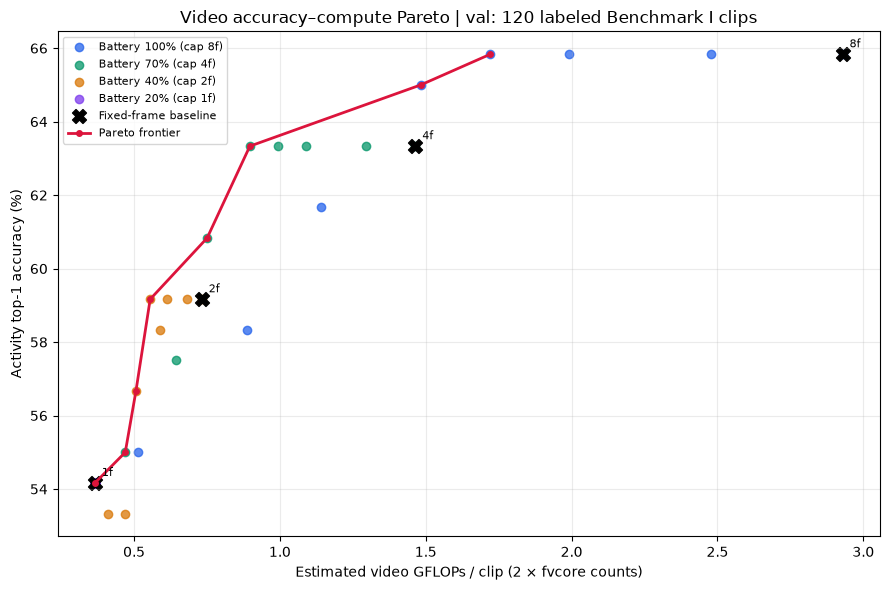

Saved plot: C:\Users\benja\Documents\CS_Master\Big Data at the Edge\Big_Data_at_the_Edge_Project\Audio\results\video_activity_pareto\video_activity_pareto_val_120.png
Non-dominated measured points:


,policy,battery_pct,confidence_threshold,frame_cap,avg_frames,activity_accuracy,avg_video_gflops_est
0,threshold_sweep,100,0.00,8,1.0000,0.5417,0.3661
11,threshold_sweep,70,0.50,4,1.2833,0.5500,0.4699
23,threshold_sweep,40,0.75,2,1.3833,0.5667,0.5065
24,threshold_sweep,40,0.85,2,1.5167,0.5917,0.5553
13,threshold_sweep,70,0.75,4,2.0500,0.6083,0.7506
14,threshold_sweep,70,0.85,4,2.4500,0.6333,0.8970
4,threshold_sweep,100,0.85,8,4.0500,0.6500,1.4829
5,threshold_sweep,100,0.90,8,4.7000,0.6583,1.7208


In [7]:
# Pareto points across ALL evaluated operating points, including the static baselines.
def mark_frontier(df):
    cost = df.avg_video_gflops_est.to_numpy(dtype=float)
    acc = df.activity_accuracy.to_numpy(dtype=float)
    dominated = np.zeros(len(df), dtype=bool)
    tol = 1e-9
    for i in range(len(df)):
        dominated[i] = np.any(
            (cost <= cost[i] + tol) & (acc >= acc[i] - tol) &
            ((cost < cost[i] - tol) | (acc > acc[i] + tol)))
    return ~dominated

comparison["pareto_frontier"] = mark_frontier(comparison)
comparison.to_csv(summary_path, index=False)
frontier = comparison[comparison.pareto_frontier].sort_values(["avg_video_gflops_est", "activity_accuracy"], ascending=[True, False])
frontier_unique = frontier.drop_duplicates(subset=["avg_video_gflops_est", "activity_accuracy"])
frontier_unique.to_csv(OUT_DIR / f"video_activity_frontier_{SPLIT}_{len(metadata)}.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 6))
colors = {100: "#2563eb", 70: "#059669", 40: "#d97706", 20: "#7c3aed"}
for b in sorted(BATTERY_FRAME_CAPS, reverse=True):
    part = comparison[(comparison.policy == "threshold_sweep") & (comparison.battery_pct == int(b*100))]
    ax.scatter(part.avg_video_gflops_est, 100*part.activity_accuracy,
               label=f"Battery {int(b*100)}% (cap {BATTERY_FRAME_CAPS[b]}f)",
               s=36, alpha=.75, color=colors[int(b*100)])
base = comparison[comparison.policy.str.startswith("fixed_")]
ax.scatter(base.avg_video_gflops_est, 100*base.activity_accuracy,
           marker="X", s=100, color="black", label="Fixed-frame baseline")
for _, r in base.iterrows():
    ax.annotate(r.policy.replace("fixed_", "").replace("_frames", "f"),
                (r.avg_video_gflops_est, r.activity_accuracy*100), xytext=(5,5), textcoords="offset points", fontsize=8)
if len(frontier_unique):
    ax.plot(frontier_unique.avg_video_gflops_est, 100*frontier_unique.activity_accuracy,
            color="crimson", linewidth=2, marker="o", markersize=4,
            label="Pareto frontier")
ax.set(xlabel="Estimated video GFLOPs / clip (2 × fvcore counts)",
       ylabel="Activity top-1 accuracy (%)",
       title=f"Video accuracy–compute Pareto | {SPLIT}: {len(metadata)} labeled Benchmark I clips")
ax.grid(alpha=.25)
ax.legend(fontsize=8, loc="best")
fig.tight_layout()
fig_path = OUT_DIR / f"video_activity_pareto_{SPLIT}_{len(metadata)}.png"
fig.savefig(fig_path, dpi=180)
plt.show()
print("Saved plot:", fig_path)
print("Non-dominated measured points:")
display(frontier_unique[["policy", "battery_pct", "confidence_threshold", "frame_cap",
                        "avg_frames", "activity_accuracy", "avg_video_gflops_est"]].round(4))

In [8]:
lr_metrics_path = ROOT / "Audio" / "results" / "mfcc_gate" / "mfcc_lr_rf_metrics_val_test.csv"
lr_cost_path = ROOT / "Audio" / "results" / "mfcc_gate" / "mfcc_lr_rf_test_comparison.csv"
if lr_metrics_path.is_file() and lr_cost_path.is_file():
    audio_metrics = pd.read_csv(lr_metrics_path)
    audio_cost = pd.read_csv(lr_cost_path)
    # Use same split label (val/test), although these remain distinct datasets and examples.
    a = audio_metrics[(audio_metrics.model == "MFCC + LR") & (audio_metrics.split == SPLIT)]
    c = audio_cost[audio_cost.model == "MFCC + LR"]
    assert len(a) == 1 and len(c) == 1
    p_trigger = 1.0 - float(a.iloc[0]["vision_skip_rate"])
    gate_est = float(c.iloc[0]["approx_frontend_gops"])  # approximate operations, not measured GPU FLOPs
    projected = comparison.copy()
    projected["audio_gate_activation_rate_different_cohort"] = p_trigger
    projected["audio_gate_approx_gops"] = gate_est
    projected["projected_combined_gops_mixed_methods"] = (
        gate_est + p_trigger * projected.avg_video_gflops_est)
    projected["projected_savings_vs_always_on_same_video_policy"] = (
        1.0 - projected.projected_combined_gops_mixed_methods / projected.avg_video_gflops_est)
    projection_path = OUT_DIR / f"illustrative_audio_video_cost_{SPLIT}_{len(metadata)}.csv"
    projected.to_csv(projection_path, index=False)
    print(f"MFCC+LR {SPLIT} gate activation (separate Benchmark II cohort): {p_trigger:.1%}")
    print(f"MFCC frontend approximate cost: {gate_est:.5f} GOPs/window")
    print("Illustrative savings relative to always running THE SAME video policy:")
    display(projected[projected.policy.eq("battery_example")][
        ["battery_pct", "confidence_threshold", "activity_accuracy", "avg_video_gflops_est",
         "projected_combined_gops_mixed_methods", "projected_savings_vs_always_on_same_video_policy"]
    ].sort_values("battery_pct", ascending=False).round(4))
    print("Saved mixed-cohort projected costs:", projection_path)
else:
    print("MFCC+LR results not found; skipping optional cost projection.")
    print("Needed:", lr_metrics_path, "and", lr_cost_path)

MFCC+LR val gate activation (separate Benchmark II cohort): 82.1%
MFCC frontend approximate cost: 0.01273 GOPs/window
Illustrative savings relative to always running THE SAME video policy:


,battery_pct,confidence_threshold,activity_accuracy,avg_video_gflops_est,projected_combined_gops_mixed_methods,projected_savings_vs_always_on_same_video_policy
9,100,0.95,0.6583,1.9924,1.6479,0.1729
19,70,0.85,0.6333,0.8970,0.7489,0.1651
29,40,0.65,0.5333,0.4699,0.3984,0.1522
39,20,0.50,0.5417,0.3661,0.3132,0.1445


Saved mixed-cohort projected costs: C:\Users\benja\Documents\CS_Master\Big Data at the Edge\Big_Data_at_the_Edge_Project\Audio\results\video_activity_pareto\illustrative_audio_video_cost_val_120.csv


In [9]:
example = comparison[comparison.policy.eq("battery_example")].sort_values("battery_pct", ascending=False)
static4 = comparison[comparison.policy.eq("fixed_4_frames")].iloc[0]
static8 = comparison[comparison.policy.eq("fixed_8_frames")].iloc[0]
display(example[["battery_pct", "frame_cap", "confidence_threshold", "avg_frames", "early_exit_rate",
                 "activity_accuracy", "activity_macro_f1", "avg_video_gflops_est"]].round(4))
print(f"Static 4-frame baseline: {static4.activity_accuracy:.1%} accuracy; {static4.avg_video_gflops_est:.4f} estimated GFLOPs")
print(f"Static 8-frame baseline: {static8.activity_accuracy:.1%} accuracy; {static8.avg_video_gflops_est:.4f} estimated GFLOPs")
print("NOTE: all points measure video compute alone, and nothing here measures sensor power or full audio+vision energy.")
settings = {
    "split": SPLIT, "n_clips": len(metadata), "seed": SEED,
    "checkpoint": str(CHECKPOINT), "checkpoint_mtime_ns": CHECKPOINT.stat().st_mtime_ns,
    "code_dir": str(VIDEO_DIR), "metadata_dir": str(METADATA_DIR), "clips_dir": str(CLIPS_DIR),
    "device": str(DEVICE), "frame_gmac_equivalents": FRAME_GMACS,
    "frame_gflops_est_2x": FRAME_GFLOPS_EST, "fvcore_unsupported_ops": UNSUPPORTED_OPERATORS,
    "sweep_thresholds": CONFIDENCE_THRESHOLDS,
    "battery_to_frame_cap": {str(k): v for k, v in BATTERY_FRAME_CAPS.items()},
    "example_battery_to_confidence_threshold": {str(k): v for k,v in BATTERY_EXAMPLE_THRESHOLDS.items()},
    "sampling": "nested video.py 8-frame prefixes; confidence exit at 1,3,6,8 with cap truncation",
    "quality_metric": "Benchmark I activity top-1 accuracy, on cropped labeled clips",
    "cost_metric": "Model-only analytic GFLOPs estimate = 2 × fvcore ops/frame × frames_used. Excludes decoding, audio, sensor power.",
}
(OUT_DIR / f"video_activity_pareto_config_{SPLIT}_{len(metadata)}.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")
print("Output folder:", OUT_DIR)

,battery_pct,frame_cap,confidence_threshold,avg_frames,early_exit_rate,activity_accuracy,activity_macro_f1,avg_video_gflops_est
9,100,8,0.95,5.4417,0.3917,0.6583,0.2285,1.9924
19,70,4,0.85,2.4500,0.5833,0.6333,0.1745,0.8970
29,40,2,0.65,1.2833,0.7167,0.5333,0.1225,0.4699
39,20,1,0.50,1.0000,0.0000,0.5417,0.1407,0.3661


Static 4-frame baseline: 63.3% accuracy; 1.4645 estimated GFLOPs
Static 8-frame baseline: 65.8% accuracy; 2.9291 estimated GFLOPs
NOTE: all points measure video compute alone, and nothing here measures sensor power or full audio+vision energy.
Output folder: C:\Users\benja\Documents\CS_Master\Big Data at the Edge\Big_Data_at_the_Edge_Project\Audio\results\video_activity_pareto
